# Validate linear summation (metamodel vs dynamic)

Compare offshore-driven **dynamic SnapWave** to the **reconstructed metamodel**
(bulk mode: WHACS bulk partition per goal, wavespectra linear sum).

Bulk output is configured in the case JSON → `metamodel.reconstruction.variables`
(HyGloW name → wavespectra stat). Set `save_spectra: true` to cache summed spectra
for notebook 11.

Comparison uses `hs`, `tp`, `dir`, and `spr` when both datasets contain them
(`val.resolve_comparison_variables`).

**Prerequisites:** fitted models (06), dynamic run (08). Use `recompute=True` after refitting.

In [1]:
import os
import time

os.environ["OMP_NUM_THREADS"] = "8"  # avoid oversubscription when using dask

import matplotlib.pyplot as plt
import xarray as xr
from utils import metamodel as mm
from utils import simulation as sim
from utils import validation as val

## Configuration

In [7]:
period = slice("2013-01-01", "2013-05-09")
offshore_name = "WHACS"
mda_n = 550  # must match a fitted mda_candidates entry
mm_set = "buoys"  # metamodel set (metamodel.sets); `sites` must belong to it
pca_variance = 0.99  # or 0.99, or {"hs": 0.99, etc}

# Site subset — isobath depth, mesh polygon, buoy id, or umbrella
sites = None  # e.g. "10m", "buoy", or a list of explicit site ids

# Metrics to compare (subset used when missing from either dataset)
compare_variables = ["hs", "tp", "dir", "spr"]

dynamic_path = (
    sim.cases_dir("dynamic") / f"Dynamic_Cases_{offshore_name}_2013_0101_0509.nc"
)

print(f"period       : {period}")
print(f"mda_n        : {mda_n}")
print(f"metamodel    : {mm_set}")
print(f"sites        : {sites}")
print(f"compare vars : {compare_variables}")
print(f"dynamic path : {dynamic_path}")

period       : slice('2013-01-01', '2013-05-09', None)
mda_n        : 550
metamodel    : buoys
sites        : None
compare vars : ['hs', 'tp', 'dir', 'spr']
dynamic path : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SWAN_CASES_Dynamic/Dynamic_Cases_WHACS_2013_0101_0509.nc


## 1 · Check models

In [8]:
mm.require_models_all(mm_set, mda_n, pca_variance=pca_variance)
print(f"common model sites: {len(mm.common_model_sites())}")

common model sites: 14


## 2 · Reconstruct metamodel (bulk)

In [9]:
t0 = time.perf_counter()
metamodel = mm.reconstruct(
    period,
    mda_n,
    metamodel=mm_set,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
    workers=8,
    save_spectra=False,  # bulk-vs-dynamic validation never reads spectra
    wind_correction=True,  # apply wind correction to dynamic cases
)
reconstruct_seconds = time.perf_counter() - t0
print(
    f"Reconstruction took {reconstruct_seconds:.2f}s for {metamodel.sizes.get('sites', '?')} sites"
)
metamodel

INFO:bluemath_tk.waves.hywaves.reconstruction:[group 2/2] sum batch 1/1 (1 sites) in 2.3s (2.3s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[group 1/2] sum batch 1/1 (1 sites) in 2.4s (2.4s elapsed)


Reconstruction took 35.49s for 2 sites


<xarray.Dataset> Size: 290kB
Dimensions:         (time: 3624, sites: 2)
Coordinates:
  * time            (time) datetime64[ns] 29kB 2013-01-01 ... 2013-05-31T23:0...
  * sites           (sites) <U30 240B 'buoy_Q1' 'buoy_EierlandseGat'
    site_source     (sites) <U7 56B 'buoy' 'buoy'
    site_label      (sites) <U5 40B 'waves' 'waves'
    site_depth      (sites) float64 16B 28.0 27.0
    site_longitude  (sites) float64 16B 4.15 4.66
    site_latitude   (sites) float64 16B 52.93 53.28
Data variables:
    hs              (time, sites) float64 58kB 1.969 1.728 1.852 ... 1.61 1.599
    tp              (time, sites) float32 29kB 7.408 7.435 7.316 ... 5.65 5.784
    dir             (time, sites) float64 58kB 241.3 250.6 244.7 ... 348.6 346.4
    spr             (time, sites) float64 58kB 19.31 24.34 20.77 ... 26.55 27.58
    wind_k          (time, sites) float64 58kB 1.148 1.183 1.203 ... 1.156 1.246

## 3 · Load dynamic reference

In [10]:
dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites, metamodel=mm_set)
dynamic = dynamic.sel(sites=site_ids).load()
dynamic

<xarray.Dataset> Size: 223kB
Dimensions:         (time: 3096, sites: 2)
Coordinates:
  * time            (time) datetime64[ns] 25kB 2013-01-01 ... 2013-05-09T23:0...
  * sites           (sites) <U30 240B 'buoy_EierlandseGat' 'buoy_Q1'
    site_source     (sites) <U7 56B 'buoy' 'buoy'
    site_label      (sites) <U5 40B 'waves' 'waves'
    site_depth      (sites) float64 16B 27.0 28.0
    site_longitude  (sites) float64 16B 4.66 4.15
    site_latitude   (sites) float64 16B 53.28 52.93
Data variables:
    hs              (time, sites) float64 50kB 1.822 1.944 1.701 ... 2.096 2.392
    tp              (time, sites) float64 50kB 7.548 7.536 7.493 ... 6.703 6.735
    dir             (time, sites) float64 50kB 246.2 240.6 249.2 ... 220.9 215.5
    spr             (time, sites) float64 50kB 26.64 26.37 26.96 ... 29.05 29.54

In [12]:
metamodel = metamodel.sel(time=dynamic.time)
metamodel

<xarray.Dataset> Size: 248kB
Dimensions:         (time: 3096, sites: 2)
Coordinates:
  * time            (time) datetime64[ns] 25kB 2013-01-01 ... 2013-05-09T23:0...
  * sites           (sites) <U30 240B 'buoy_Q1' 'buoy_EierlandseGat'
    site_source     (sites) <U7 56B 'buoy' 'buoy'
    site_label      (sites) <U5 40B 'waves' 'waves'
    site_depth      (sites) float64 16B 28.0 27.0
    site_longitude  (sites) float64 16B 4.15 4.66
    site_latitude   (sites) float64 16B 52.93 53.28
Data variables:
    hs              (time, sites) float64 50kB 1.969 1.728 1.852 ... 2.427 1.881
    tp              (time, sites) float32 25kB 7.408 7.435 7.316 ... 6.388 6.424
    dir             (time, sites) float64 50kB 241.3 250.6 244.7 ... 217.9 222.6
    spr             (time, sites) float64 50kB 19.31 24.34 20.77 ... 29.94 34.16
    wind_k          (time, sites) float64 50kB 1.148 1.183 1.203 ... 1.435 1.354

## 4 · Compare

In [13]:
variables = val.resolve_comparison_variables(
    metamodel,
    dynamic,
    variables=compare_variables,
)
print(f"Comparing: {variables}")

result = val.compare(
    reference=dynamic,
    estimate=metamodel,
    variables=variables,
    reference_label=val.DYNAMIC_REFERENCE_LABEL,
    estimate_label="Linear summation",
    pca_variance=pca_variance,
)
result.metrics

Comparing: ['hs', 'tp', 'dir', 'spr']


,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,rrmse,si,r,r2,reference_label,estimate_label
0,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_Q1,buoy,waves,hs,Hs,3096,0.016105,0.184542,0.148173,0.132277,0.961274,0.910470,Dynamic SWAN,Linear summation
1,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_Q1,buoy,waves,tp,Tp,3092,-0.052905,0.816759,0.120805,0.114635,0.929845,0.862168,Dynamic SWAN,Linear summation
2,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_Q1,buoy,waves,dir,Dir,3096,-1.210297,24.905587,NaN,NaN,NaN,0.894751,Dynamic SWAN,Linear summation
3,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_Q1,buoy,waves,spr,Spr,3092,-4.744904,10.957336,0.308852,0.269185,0.362719,-0.370917,Dynamic SWAN,Linear summation
4,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,hs,Hs,3096,-0.010695,0.134947,0.108882,0.096814,0.978438,0.953853,Dynamic SWAN,Linear summation
5,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,tp,Tp,3094,-0.126143,0.877379,0.126457,0.119219,0.923127,0.842996,Dynamic SWAN,Linear summation
6,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,dir,Dir,3096,1.012971,22.744725,NaN,NaN,NaN,0.899894,Dynamic SWAN,Linear summation
7,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,spr,Spr,3094,-3.797311,11.052618,0.323555,0.293785,0.282284,-0.500705,Dynamic SWAN,Linear summation


## 5 · Save metrics

In [14]:
period = "2013-01-01_2013-05-09"  # for file naming
period

'2013-01-01_2013-05-09'

In [15]:
metrics_out = result.metrics.copy()
metrics_out.insert(0, "period", period)
metrics_out.insert(1, "metamodel", mm_set)
metrics_out.insert(2, "mda_candidate", mda_n)
metrics_out.insert(3, "offshore_name", offshore_name)
metrics_out["n_sites"] = int(metamodel.sizes["sites"])
# Wall time for mm.reconstruct() above — near-zero if these sites/period
# were already cached from a previous run, not a fresh-simulation cost.
metrics_out["reconstruct_seconds"] = reconstruct_seconds

out_path = val.metamodel_validation_path(period, mm_set)
out_path.parent.mkdir(parents=True, exist_ok=True)
metrics_out.to_csv(out_path, index=False)
print(f"Wrote {out_path}")

Wrote /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/metamodel_validation/linear_summation_buoys_2013-01-01_2013-05-09.csv


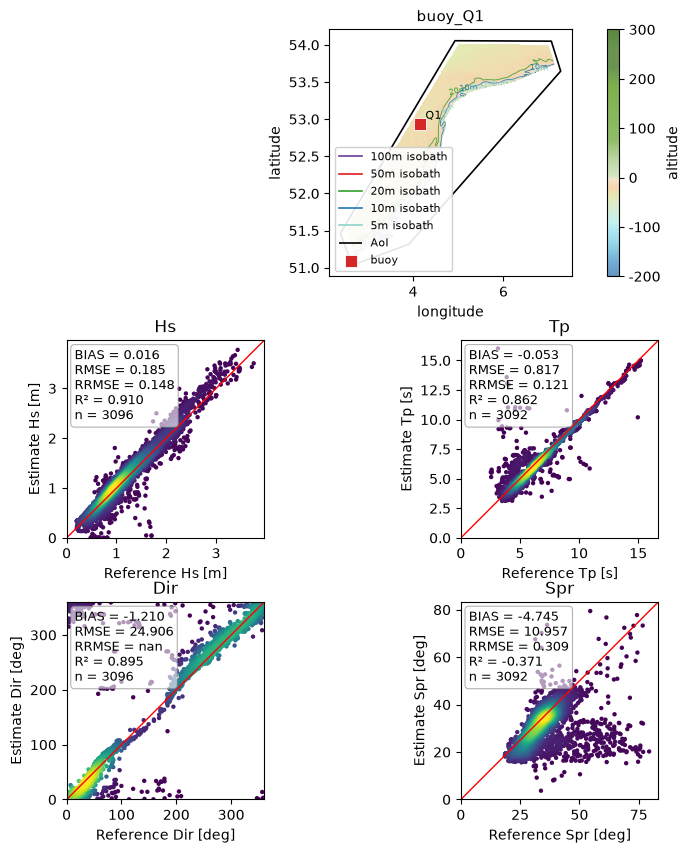

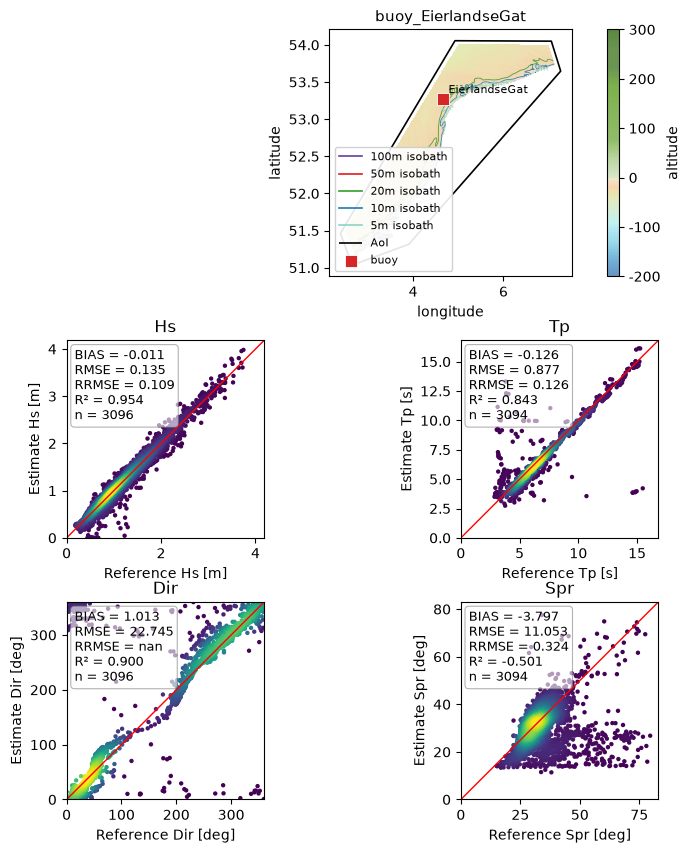

In [16]:
result.plot_all(variables=variables)
plt.show()